# Sachs et al. (2005) — Causal Discovery Methods Comparison

Benchmarks observational and interventional causal discovery methods on the Sachs protein signaling dataset using continuous log-transformed flow cytometry data.

The Sachs protein dataset contains concentration levels of 11 proteins found in human immune cells measured in flow cytometry data. 

In contrast to the original paper, where the variables were first discretized and then a discrete Bayesian network algorithm was employed, here we have employed causal discovery methods for continuous variables for both the log-transformed and raw concentration values. 

There are several plausble ground-truth DAGs for this dataset. For this experiment, I used the 18-edge version from the bnlearn library. 

| Method | Uses interventions? | Knows targets? |
|--------|--------------------|-----------------|
| PC | No | — |
| DirectLiNGAM | No | — |
| ICA-LiNGAM | No | — |
| GIES | Yes | Yes |
| UT-IGSP | Yes | No |


## Experimental Conditions
There are 9 different environments, each corresponding to an experimental condition. 



| # | Condition key | Full name | Reagent effect | Targets (According to Sachs et al) |
|---|--------------|-----------|----------------|---------|
| 1 | `cd3cd28` * | anti-CD3 + anti-CD28 | T-cell activation (baseline) | PKC, PKA |
| 2 | `cd3cd28icam2` | anti-CD3/CD28 + ICAM-2 | Adds co-stimulation via ICAM-2 | PKC, PKA |
| 3 | `cd3cd28+u0126` | anti-CD3/CD28 + U0126 | MEK inhibitor | PKC, PKA, Mek |
| 4 | `cd3cd28+aktinhib` | anti-CD3/CD28 + AKT inhibitor | AKT inhibitor | PKC, PKA, Akt |
| 5 | `cd3cd28+g0076` | anti-CD3/CD28 + G06976 | PKC inhibitor | PKC, PKA |
| 6 | `cd3cd28+psitect` | anti-CD3/CD28 + psitectorigenin | PKA inhibitor | PKC, PKA |
| 7 | `cd3cd28+ly` | anti-CD3/CD28 + LY294002 | PI3K inhibitor → ↓ PIP3 | PKC, PKA, PIP3 |
| 8 | `pma` | Phorbol 12-myristate 13-acetate (PMA) | PKC activator | PKC |
| 9 | `b2camp` | β2-cyclic AMP (β2cAMP) | PKA activator | PKA |

* Indicates that this environment was regarded as the observational environment, following Squires (2020)



## Run LiNGAM on the observational environment, it should hopefully not work....

## Random subsaple of the same size for the

In [8]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
from castle.metrics import MetricsDAG
from load_sachs import *
from castle.datasets import DAG
import matplotlib.pyplot as plt
# Load the sachs data. The load_sachs function returns a dataframe with all conditions and protein columns.
all_data = load_sachs(xls_dir='../data/original_data', use_western_blot=False, transform = False)

# Get observational subset: 
X_obs = all_data[all_data["condition"] == "cd3cd28"].values[:, :-1].astype(float) # Observational data (no targets)
print(f'Observational data shape: {X_obs.shape}')

# Make a list of interventional subsets, one per condition (excluding the observational condition).
X_int_list = []
for condition in all_data["condition"].unique():
    if condition != "cd3cd28":  # Skip observational condition
        X_int = all_data[all_data["condition"] == condition].values[:, :-1]
        X_int_list.append((condition, X_int))
        print(f'Interventional data for {condition} shape: {X_int.shape}')

# Squires (2020) subset used in the UT-IGSP paper real-data analysis.
# Excludes cd3cd28icam2, pma, and b2camp; assigns one target node per condition.
# Target indices are 0-based positions in PROTEINS.
# Source: https://github.com/csquires/utigsp/blob/master/real_data_analysis/sachs/

SQUIRES_SUBSET = {
    "cd3cd28":          [],  # observational (no targets)
    "cd3cd28+u0126":    [1], # Mek   (MEK inhibitor)
    "cd3cd28+psitect":  [3], # PIP2
    "cd3cd28+ly":       [4], # PIP3  (PI3K inhibitor)
    "cd3cd28+aktinhib": [6], # Akt   (AKT inhibitor)
    "cd3cd28+g0076":    [8], # PKC   (PKC inhibitor)
}

# Subset the data according to the Squires (2020) subset.
subset_conditions = list(SQUIRES_SUBSET.keys())
chandler_subset = all_data[all_data["condition"].isin(subset_conditions)]
assert set(chandler_subset["condition"].unique()) == set(subset_conditions), "Subset conditions do not match expected conditions."

print(chandler_subset.head())

# "Raf","Mek","PLCg","PIP2","PIP3","Erk","Akt","PKA","PKC","P38","JNK"


Observational data shape: (752, 11)
Interventional data for cd3cd28icam2 shape: (789, 11)
Interventional data for cd3cd28+aktinhib shape: (782, 11)
Interventional data for cd3cd28+g0076 shape: (622, 11)
Interventional data for cd3cd28+psitect shape: (713, 11)
Interventional data for cd3cd28+u0126 shape: (674, 11)
Interventional data for cd3cd28+ly shape: (732, 11)
Interventional data for pma shape: (785, 11)
Interventional data for b2camp shape: (607, 11)
    Raf   Mek   PLCg   PIP2   PIP3    Erk   Akt    PKA    PKC   P38   Jnk  \
0  26.4  13.2   8.82  18.30  58.80   6.61  17.0  414.0  17.00  44.9  40.0   
1  35.9  16.5  12.30  16.80   8.13  18.60  32.5  352.0   3.37  16.5  61.5   
2  59.4  44.1  14.60  10.20  13.00  14.90  32.5  403.0  11.40  31.9  19.5   
3  73.0  82.8  23.10  13.50   1.29   5.83  11.8  528.0  13.70  28.6  23.1   
4  33.7  19.8   5.19   9.73  24.80  21.10  46.1  305.0   4.66  25.7  81.3   

  condition  
0   cd3cd28  
1   cd3cd28  
2   cd3cd28  
3   cd3cd28  
4   cd3

In [9]:
true_amat = get_ground_truth_bnlearn().values.astype(int)
print(true_amat)

[[0 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]
 [0 0 0 1 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 1 1 0 0 1 1]
 [1 1 0 0 0 0 0 1 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0]]


# Data Analysis

Here, I've used the raw data without any transformations. Most proteins have roughly log-normal raw distributions, except for PKA, which is bimodal. 
Applying a log-transform yields better results 

In [10]:
chandler_subset.groupby("condition").describe() 

Raf                                                       \
                  count        mean         std    min     25%    50%    75%   
condition                                                                      
cd3cd28           752.0   55.201489   29.269163   1.61   35.20   50.9   71.7   
cd3cd28+aktinhib  782.0   53.379476   32.575130   1.00   28.90   48.5   73.7   
cd3cd28+g0076     622.0  366.777653  318.685767  13.10  169.00  259.0  433.0   
cd3cd28+ly        732.0   53.400205   32.624797   1.00   28.90   48.3   73.7   
cd3cd28+psitect   713.0   56.473170   29.939630   1.00   35.20   56.2   74.3   
cd3cd28+u0126     674.0  351.151380  344.648277   4.45  121.25  227.0  437.0   

                            Mek              ...    P38            Jnk  \
                     max  count        mean  ...    75%     max  count   
condition                                    ...                         
cd3cd28            181.0  752.0   27.156011  ...   39.6    91.4  752.0   
cd3cd28+aktinhib   167.0  782.0   26.943504  ...   35.5    77.7  782.0   
cd3cd28+g0076     1762.0  622.0  569.839068  ...  920.0  4656.0  622.0   
cd3cd28+ly         167.0  732.0   26.744686  ...   39.6    90.6  732.0   
cd3cd28+psitect    175.0  713.0   28.774628  ...   51.9   129.0  713.0   
cd3cd28+u0126     1685.0  674.0  517.324318  ...   39.2    84.3  674.0   

                                                                                
                        mean         std   min     25%     50%     75%     max  
condition                                                                       
cd3cd28            34.444242   33.343604   1.0   12.00   19.50   51.90   167.0  
cd3cd28+aktinhib   11.683696    9.620581   1.0    6.44   10.00   13.80    83.5  
cd3cd28+g0076     386.958039  362.584743  12.9  147.75  246.00  461.00  1963.0  
cd3cd28+ly         24.774577   29.275544   1.0    7.64   13.40   24.45   147.0  
cd3cd28+psitect    31.429088   28.533081   1.0   10.90   19.80   44.10   132.0  
cd3cd28+u0126      13.664169   18.230891   1.0    5.05    8.58   13.50   117.0  

[6 rows x 88 columns]

# 0. Causal discovery on observational data only 

In [11]:
# Visualize the observational data distribution. 
# Check data distributions for each protein (raw concentration values).


# Data Analysis
from castle.algorithms import PC, DirectLiNGAM, ICALiNGAM

models = {
    'DirectLiNGAM': DirectLiNGAM(),
    'ICA-LiNGAM':   ICALiNGAM(),
}

results = {}

print(f'Running causal discovery algorithms on the observational data (n={X_obs.shape[0]} cells)...')

for name, model in models.items():
    model.learn(X_obs)
    results[name] = {}
    results[name]['causal_matrix'] = model.causal_matrix
    m = MetricsDAG(model.causal_matrix, true_amat).metrics
    print(f'{name:15s}  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')
    results[name]['metrics'] = {'shd': m['shd'], 'tpr': m['tpr'], 'fdr': m['fdr'], 'f1': m['F1']}



2026-04-13 14:40:58,908 - /Users/f007ybg/.venvs/cd-intervention-venv/lib/python3.13/site-packages/castle/backend/__init__.py[line:36] - INFO: You can use `os.environ['CASTLE_BACKEND'] = backend` to set the backend(`pytorch` or `mindspore`).
2026-04-13 14:40:59,694 - /Users/f007ybg/.venvs/cd-intervention-venv/lib/python3.13/site-packages/castle/algorithms/__init__.py[line:36] - INFO: You are using ``pytorch`` as the backend.


Running causal discovery algorithms on the observational data (n=752 cells)...
DirectLiNGAM     SHD=15  TPR=0.118  FDR=0.500  F1=0.191
ICA-LiNGAM       SHD=12  TPR=0.294  FDR=0.375  F1=0.400


## 1. Pooled Data, No Labels. 

Algorithms used:
- PC
- DirectLiNGAM
- ICA-LiNGAM

Note: ICA-LiNGAM uses FastICA, the results of the optimization step for FastICA depend on intialization so that the overall results from ICA-LiNGAM vary. 



In [12]:

print(f'Running causal discovery algorithms on all data (n={all_data.shape[0]} cells)...')

X_all = all_data.drop(columns=['condition'])

models = {
    'DirectLiNGAM': DirectLiNGAM(),
    'ICA-LiNGAM':   ICALiNGAM(),
}

results = {}


for name, model in models.items():
    model.learn(X_all)
    results[name] = {}
    results[name]['causal_matrix'] = model.causal_matrix
    m = MetricsDAG(model.causal_matrix, true_amat).metrics
    print(f'{name:15s}  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')
    results[name]['metrics'] = {'shd': m['shd'], 'tpr': m['tpr'], 'fdr': m['fdr'], 'f1': m['F1']}




Running causal discovery algorithms on all data (n=6456 cells)...
DirectLiNGAM     SHD=17  TPR=0.235  FDR=0.600  F1=0.296
ICA-LiNGAM       SHD=17  TPR=0.412  FDR=0.611  F1=0.400


In [13]:
data_no_labels = chandler_subset.drop(columns=['condition'])

# Check for exact duplicate values per column in the pooled data
print(f"Pooled data shape: {data_no_labels.shape}")
print(f"\nDuplicate rows (entire row identical): {data_no_labels.duplicated().sum()}")

print("\nPer-column duplicate value counts:")
print(f"{'Protein':<10} {'Total':>8} {'Unique':>8} {'Duplicates':>12} {'Dup %':>8}")
print("-" * 50)
for col in data_no_labels.columns:
    total = len(data_no_labels[col])
    n_unique = data_no_labels[col].nunique()
    n_dup = total - n_unique
    print(f"{col:<10} {total:>8} {n_unique:>8} {n_dup:>12} {100*n_dup/total:>7.2f}%")

print(f'Running causal discovery algorithms on the Squires subset (obs + 5 intv. envs)...')

models = {
    'DirectLiNGAM': DirectLiNGAM(),
    'ICA-LiNGAM':   ICALiNGAM(),
}

results = {}


for name, model in models.items():
    model.learn(data_no_labels)
    results[name] = {}
    results[name]['causal_matrix'] = model.causal_matrix
    m = MetricsDAG(model.causal_matrix, true_amat).metrics
    print(f'{name:15s}  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')
    results[name]['metrics'] = {'shd': m['shd'], 'tpr': m['tpr'], 'fdr': m['fdr'], 'f1': m['F1']}



Pooled data shape: (4275, 11)

Duplicate rows (entire row identical): 0

Per-column duplicate value counts:
Protein       Total   Unique   Duplicates    Dup %
--------------------------------------------------
Raf            4275      611         3664   85.71%
Mek            4275      650         3625   84.80%
PLCg           4275      683         3592   84.02%
PIP2           4275      808         3467   81.10%
PIP3           4275      514         3761   87.98%
Erk            4275      535         3740   87.49%
Akt            4275      554         3721   87.04%
PKA            4275      718         3557   83.20%
PKC            4275      651         3624   84.77%
P38            4275      655         3620   84.68%
Jnk            4275      731         3544   82.90%
Running causal discovery algorithms on the Squires subset (obs + 5 intv. envs)...
DirectLiNGAM     SHD=25  TPR=0.294  FDR=0.773  F1=0.256
ICA-LiNGAM       SHD=22  TPR=0.412  FDR=0.720  F1=0.333


## 2. GIES (Known Intervention Targets)

Greedy Interventional Equivalence Search using all 9 environments with their known targets.
`cd3cd28` is treated as observational (empty target set).

In [14]:
import gies

gies_data = [X_obs.astype(float)] + [
    chandler_subset[chandler_subset["condition"] == cond][PROTEINS].values.astype(float)
    for cond in SQUIRES_SUBSET if cond != "cd3cd28"
]


gies_targets = [[]] + [v for k, v in SQUIRES_SUBSET.items() if k != "cd3cd28"]
print(gies_targets)

estimate, score = gies.fit_bic(gies_data, gies_targets) 

# Store results 
results['GIES'] = {}
m = MetricsDAG(estimate, true_amat).metrics
results['GIES']['metrics'] = m
results['GIES']['causal_matrix'] = estimate
print(f'\nGIES  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')

[[], [1], [3], [4], [6], [8]]

GIES  SHD=19  TPR=0.235  FDR=0.733  F1=0.188


## 3. UT-IGSP (Unknown Intervention Targets)

Same data split as GIES, but targets are **not** provided — UT-IGSP infers them from distributional shifts.

In [15]:
from causaldag import unknown_target_igsp
from causaldag.utils.ci_tests import gauss_ci_suffstat, gauss_ci_test, MemoizedCI_Tester # # Change to nonparametric test. 
from causaldag.utils.invariance_tests import gauss_invariance_suffstat, gauss_invariance_test, MemoizedInvarianceTester #hsic_invariance_test, hsic_invariance_suffstat,  # Change to nonparametric test. 
from causaldag import igsp

X_int_igsp = [ chandler_subset[chandler_subset["condition"] == cond][PROTEINS].values.astype(float)
    for cond in SQUIRES_SUBSET if cond != "cd3cd28" 
] 

targets = [[v for k, v in SQUIRES_SUBSET.items() if k != "cd3cd28"]]

# Gaussian invariance test version of UT-IGSP, note that the output varies based on the random order of the environments, so we run it multiple times and report the average and standard deviation of the metrics across runs.
obs_suffstat        = gauss_ci_suffstat(X_obs)
invariance_suffstat = gauss_invariance_suffstat(X_obs, X_int_igsp)
ci_tester           = MemoizedCI_Tester(gauss_ci_test, obs_suffstat, alpha=0.05)
invariance_tester   = MemoizedInvarianceTester(gauss_invariance_test, invariance_suffstat, alpha=0.05)
setting_list = [
    dict(known_interventions=set(targets))
    for cond, targets in SQUIRES_SUBSET.items()
    if cond != "cd3cd28"
]


N_RUNS = 10
utigsp_metrics = []
utigsp_adj_estimates = []

for run in range(N_RUNS):

    est_dag, est_targets_list = unknown_target_igsp(
        setting_list, set(range(len(PROTEINS))), ci_tester, invariance_tester
    )

    adj = est_dag.to_amat()[0]
    m   = MetricsDAG(adj, true_amat).metrics
    print(f'UT-IGSP  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')
    utigsp_metrics.append(m)
    utigsp_adj_estimates.append(adj)
    #print(f'UT-IGSP  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')

average_metrics_igsp = {
    'shd': np.nanmean([m['shd'] for m in utigsp_metrics]),
    'tpr': np.nanmean([m['tpr'] for m in utigsp_metrics]),
    'fdr': np.nanmean([m['fdr'] for m in utigsp_metrics]),
    'f1': np.nanmean([m['F1'] for m in utigsp_metrics]),
}
std_metrics = {
    'shd': np.nanstd([m['shd'] for m in utigsp_metrics]),
    'tpr': np.nanstd([m['tpr'] for m in utigsp_metrics]),
    'fdr': np.nanstd([m['fdr'] for m in utigsp_metrics]),
    'f1': np.nanstd([m['F1'] for m in utigsp_metrics]),
}   


UT-IGSP  SHD=16  TPR=0.118  FDR=0.778  F1=0.154
UT-IGSP  SHD=13  TPR=0.294  FDR=0.444  F1=0.385
UT-IGSP  SHD=17  TPR=0.059  FDR=0.889  F1=0.077
UT-IGSP  SHD=18  TPR=0.000  FDR=1.000  F1=nan


/Users/f007ybg/.venvs/cd-intervention-venv/lib/python3.13/site-packages/castle/metrics/evaluation.py:235: RuntimeWarning: invalid value encountered in scalar divide
  F1 = 2*(recall*precision)/(recall+precision)


UT-IGSP  SHD=16  TPR=0.118  FDR=0.778  F1=0.154
UT-IGSP  SHD=13  TPR=0.294  FDR=0.444  F1=0.385
UT-IGSP  SHD=17  TPR=0.059  FDR=0.889  F1=0.077
UT-IGSP  SHD=17  TPR=0.059  FDR=0.889  F1=0.077
UT-IGSP  SHD=14  TPR=0.235  FDR=0.556  F1=0.308
UT-IGSP  SHD=15  TPR=0.176  FDR=0.667  F1=0.231


In [16]:
from causaldag.structure_learning.dag.gsp import igsp

for i in range(N_RUNS):
    setting_list = [
        dict(interventions={1}),  # cd3cd28+u0126  → Mek
        dict(interventions={7}),  # cd3cd28+psitect → PIP2
        dict(interventions={4}),  # cd3cd28+ly      → PIP3
        dict(interventions={6}),  # cd3cd28+aktinhib → Akt
        dict(interventions={8}),  # cd3cd28+g0076   → PKC
    ]

    est_dag = igsp(
        setting_list, set(range(len(PROTEINS))), ci_tester, invariance_tester
    )
    adj = est_dag.to_amat()[0]

    m   = MetricsDAG(adj, true_amat).metrics
    print(f'IGSP with known targets  SHD={m["shd"]:2d}  TPR={m["tpr"]:.3f}  FDR={m["fdr"]:.3f}  F1={m["F1"]:.3f}')

IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=14  TPR=0.235  FDR=0.556  F1=0.308
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=15  TPR=0.176  FDR=0.667  F1=0.231
IGSP with known targets  SHD=14  TPR=0.235  FDR=0.556  F1=0.308


## 4. Subsampling comparison — SHD vs. samples per environment

Draw `s` samples per environment (bootstrap, 30 draws), run all four methods, plot mean SHD ± 1 SD.

- **Pooling methods** (LiNGAM) see `s × 6` total samples with no labels.
- **Label-aware methods** (GIES, IGSP) see `s` samples per environment with known targets.

UT-IGSP is omitted here due to runtime and high variance (see earlier cells).

In [17]:
import warnings

SAMPLE_SIZES = [50, 100, 200, 400, 'all']
N_BOOTSTRAP  = 30

# Pre-organise data by condition (Squires subset only)
cond_data = {
    cond: chandler_subset[chandler_subset['condition'] == cond][PROTEINS].values.astype(float)
    for cond in SQUIRES_SUBSET
}

# Fixed IGSP setting list derived from SQUIRES_SUBSET (consistent with gies_targets)
igsp_settings = [
    dict(interventions=set(targets))
    for cond, targets in SQUIRES_SUBSET.items()
    if cond != 'cd3cd28'
]
gies_targets_sub = [[]] + [v for k, v in SQUIRES_SUBSET.items() if k != 'cd3cd28']

# Results: method -> sample_size -> list of SHD across bootstrap draws
METHODS_SWEEP = ['dlingam', 'icalingam', 'gies', 'igsp']
boot_results  = {m: {s: [] for s in SAMPLE_SIZES} for m in METHODS_SWEEP}

rng = np.random.default_rng(0)

warnings.filterwarnings('ignore')   # suppress castle FutureWarnings during loop

for s in SAMPLE_SIZES:
    print(f'n_per_env = {s!s:<6}', end='  ', flush=True)
    for b in range(N_BOOTSTRAP):
        # --- subsample each condition ---
        sub = {}
        for cond, data in cond_data.items():
            n_avail = len(data)
            n_draw  = n_avail if s == 'all' else min(s, n_avail)
            idx     = rng.choice(n_avail, size=n_draw, replace=False)
            sub[cond] = data[idx]

        X_obs_b = sub['cd3cd28']
        X_int_b = [sub[cond] for cond in SQUIRES_SUBSET if cond != 'cd3cd28']
        X_pool  = np.vstack(list(sub.values()))  # all conditions pooled, no labels

        # DirectLiNGAM
        try:
            mdl = DirectLiNGAM(); mdl.learn(X_pool)
            shd = MetricsDAG(mdl.causal_matrix, true_amat).metrics['shd']
        except Exception:
            shd = np.nan
        boot_results['dlingam'][s].append(shd)

        # ICA-LiNGAM
        try:
            mdl = ICALiNGAM(); mdl.learn(X_pool)
            shd = MetricsDAG(mdl.causal_matrix, true_amat).metrics['shd']
        except Exception:
            shd = np.nan
        boot_results['icalingam'][s].append(shd)

        # GIES (known targets)
        try:
            est, _ = gies.fit_bic([X_obs_b] + X_int_b, gies_targets_sub)
            shd = MetricsDAG(est, true_amat).metrics['shd']
        except Exception:
            shd = np.nan
        boot_results['gies'][s].append(shd)

        # IGSP (known targets)
        try:
            obs_ss  = gauss_ci_suffstat(X_obs_b)
            inv_ss  = gauss_invariance_suffstat(X_obs_b, X_int_b)
            ci_t    = MemoizedCI_Tester(gauss_ci_test, obs_ss, alpha=0.05)
            inv_t   = MemoizedInvarianceTester(gauss_invariance_test, inv_ss, alpha=0.05)
            est_dag = igsp(igsp_settings, set(range(len(PROTEINS))), ci_t, inv_t)
            shd     = MetricsDAG(est_dag.to_amat()[0], true_amat).metrics['shd']
        except Exception:
            shd = np.nan
        boot_results['igsp'][s].append(shd)

    # brief per-size summary
    for m in METHODS_SWEEP:
        vals = boot_results[m][s]
        print(f'{m}={np.nanmean(vals):.1f}', end='  ')
    print()

warnings.filterwarnings('default')
print('Done.')

n_per_env = 50      dlingam=17.4  icalingam=19.3  gies=18.3  igsp=15.6  
n_per_env = 100     dlingam=19.1  icalingam=21.0  gies=17.6  igsp=15.0  
n_per_env = 200     dlingam=20.1  icalingam=21.0  gies=17.6  igsp=14.6  
n_per_env = 400     dlingam=21.6  icalingam=22.5  gies=17.8  igsp=15.5  
n_per_env = all     dlingam=25.0  icalingam=22.0  gies=19.0  igsp=15.5  
Done.


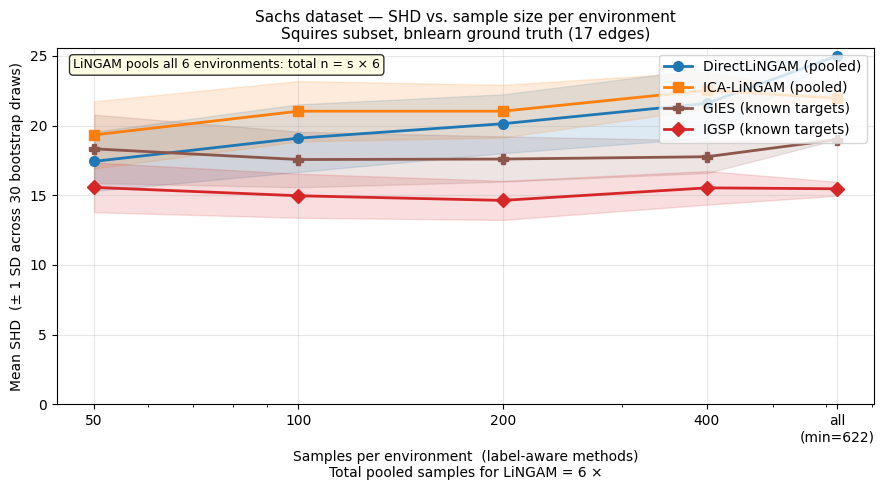

In [18]:
SWEEP_LABELS = {
    'dlingam':   'DirectLiNGAM (pooled)',
    'icalingam': 'ICA-LiNGAM (pooled)',
    'gies':      'GIES (known targets)',
    'igsp':      'IGSP (known targets)',
    'random_guess_ica': 'Random guess (same # edges as ICA-LiNGAM)',
    'random_guess_groundtruth': 'Random guess (same # edges as true graph)',
}
SWEEP_COLORS = {
    'dlingam':   '#1f77b4',
    'icalingam': '#ff7f0e',
    'gies':      '#8c564b',
    'igsp':      '#d62728',
    'random_guess_ica': '#9467bd',
    'random_guess_groundtruth': '#8c564b'
}
SWEEP_MARKERS = {
    'dlingam':   'o',
    'icalingam': 's',
    'gies':      'P',
    'igsp':      'D',
    'random_guess_ica': 'X',
    'random_guess_groundtruth': 'x'
}

# Map 'all' to the actual minimum per-environment size for the x-axis
min_env_n  = min(len(v) for v in cond_data.values())
x_numeric  = [s if s != 'all' else min_env_n for s in SAMPLE_SIZES]
x_ticklabs = [str(s) if s != 'all' else f'all\n(min={min_env_n})' for s in SAMPLE_SIZES]

fig, ax = plt.subplots(figsize=(9, 5))

for m in METHODS_SWEEP:
    means = np.array([np.nanmean(boot_results[m][s]) for s in SAMPLE_SIZES])
    stds  = np.array([np.nanstd( boot_results[m][s]) for s in SAMPLE_SIZES])
    nan_f = [np.mean(np.isnan(boot_results[m][s])) for s in SAMPLE_SIZES]

    ax.plot(x_numeric, means,
            color=SWEEP_COLORS[m], marker=SWEEP_MARKERS[m],
            lw=2, markersize=7, label=SWEEP_LABELS[m])
    ax.fill_between(x_numeric, means - stds, means + stds,
                    color=SWEEP_COLORS[m], alpha=0.15)
    # Mark any size where >10% of runs returned NaN
    for xi, nf in zip(x_numeric, nan_f):
        if nf > 0.1:
            ax.annotate(f'{nf:.0%} fail', xy=(xi, means[x_numeric.index(xi)]),
                        fontsize=7, color=SWEEP_COLORS[m], ha='center', va='bottom')

# Note on total n seen by pooling methods
ax.text(0.02, 0.97,
        'LiNGAM pools all 6 environments: total n = s × 6',
        transform=ax.transAxes, fontsize=9, va='top',
        bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.8))

ax.set_xscale('log')
ax.set_xticks(x_numeric)
ax.set_xticklabels(x_ticklabs)
ax.set_xlabel('Samples per environment  (label-aware methods)\n'
              'Total pooled samples for LiNGAM = 6 ×', fontsize=10)
ax.set_ylabel('Mean SHD  (± 1 SD across 30 bootstrap draws)', fontsize=10)
ax.set_title('Sachs dataset — SHD vs. sample size per environment\n'
             'Squires subset, bnlearn ground truth (17 edges)', fontsize=11)
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('sachs_subsample_comparison.png', dpi=150, bbox_inches='tight')
plt.savefig('sachs_subsample_comparison.pdf', bbox_inches='tight')
plt.show()

## 5. Asymmetric pooling sweep

**Same total n for both sides**, but drawn from different pools:

- **LiNGAM**: `n` samples drawn from the full dataset (all 9 conditions, 6456 total) — no labels used.
- **GIES / IGSP**: `n` samples drawn from the Squires subset (4275 total), split by condition label.

This is the fairest comparison for the pooling hypothesis: LiNGAM can leverage all available data, while label-aware methods are constrained to the labeled subset.

In [26]:
import warnings, matplotlib.pyplot as plt

TOTAL_SIZES  = [200, 500, 1000, 2000, 4000, 'all']
N_BOOTSTRAP2 = 100

X_full  = all_data[PROTEINS].values.astype(float)          # 6456 × 11, all conditions
sq_data = chandler_subset.reset_index(drop=True)           # 4275 × 12, Squires only

igsp_settings2    = [dict(interventions=set(t)) for t in gies_targets_sub[1:]]  # skip []
gies_targets_sub2 = gies_targets_sub                       # [[],[1],[3],[4],[6],[8]]

METHODS2     = ['dlingam', 'icalingam', 'gies', 'igsp', 'random_guess_ica', 'random_guess_groundtruth']
# random_guess_ica: random DAG with same number of edges as ICA-LiNGAM estimate (pooled)
# random_guess_groundtruth: random DAG with same number of edges as true graph (for reference
boot2        = {m: {s: [] for s in TOTAL_SIZES} for m in METHODS2}

rng2 = np.random.default_rng(1)
warnings.filterwarnings('ignore')

for s in TOTAL_SIZES:
    print(f'total_n = {str(s):<6}', end='  ', flush=True)
    for _ in range(N_BOOTSTRAP2):

        # --- LiNGAM: subsample from full pool ---
        n_full = len(X_full) if s == 'all' else min(s, len(X_full))
        X_pool_b = X_full[rng2.choice(len(X_full), n_full, replace=False)]

        # --- GIES/IGSP: subsample from Squires, split by condition ---
        n_sq = len(sq_data) if s == 'all' else min(s, len(sq_data))
        sq_b = sq_data.iloc[rng2.choice(len(sq_data), n_sq, replace=False)]

        X_obs_b = sq_b[sq_b['condition'] == 'cd3cd28'][PROTEINS].values.astype(float)
        X_int_b = [
            sq_b[sq_b['condition'] == cond][PROTEINS].values.astype(float)
            for cond in SQUIRES_SUBSET if cond != 'cd3cd28'
        ]
        # drop environments that ended up empty after subsampling
        nonempty = [(xi, t) for xi, t in zip(X_int_b, gies_targets_sub2[1:]) if len(xi) > 0]
        if nonempty:
            X_int_b_f, tgts_f = zip(*nonempty)
            X_int_b_f, tgts_f = list(X_int_b_f), list(tgts_f)
        else:
            X_int_b_f, tgts_f = [], []
        gies_data_b = [X_obs_b] + X_int_b_f
        gies_tgts_b = [[]] + tgts_f
        igsp_set_b  = [dict(interventions=set(t)) for t in tgts_f]

        # DirectLiNGAM
        try:
            mdl = DirectLiNGAM(); mdl.learn(X_pool_b)
            shd = MetricsDAG(mdl.causal_matrix, true_amat).metrics['shd']
        except Exception: shd = np.nan
        boot2['dlingam'][s].append(shd)

        # ICA-LiNGAM
        try:
            mdl = ICALiNGAM(); mdl.learn(X_pool_b)
            shd = MetricsDAG(mdl.causal_matrix, true_amat).metrics['shd']
        except Exception: shd = np.nan
        boot2['icalingam'][s].append(shd)

        # GIES
        try:
            est, _ = gies.fit_bic(gies_data_b, gies_tgts_b)
            shd = MetricsDAG(est, true_amat).metrics['shd']
        except Exception: shd = np.nan
        boot2['gies'][s].append(shd)

        # Random guess with same number of edges as ICA-LiNGAM estimate (pooled)
        try: 
            n_edges_ica = np.sum(mdl.causal_matrix)  # number of edges in the estimated graph
            random_guess_dag = DAG.erdos_renyi(len(PROTEINS), n_edges_ica )
            shd = MetricsDAG(random_guess_dag, true_amat).metrics['shd']
        except Exception: shd = np.nan
        boot2['random_guess_ica'][s].append(shd)

        
        # Random guess with same number of edges as true graph (for reference)
        try:
            n_edges_true = np.sum(true_amat)  # number of edges in the true graph
            random_guess_true = DAG.erdos_renyi(len(PROTEINS), n_edges_true ) # Expected number of edges is computed by setting p = 2 * edges / d^2, so we have to add 1. 
            shd = MetricsDAG(random_guess_true, true_amat).metrics['shd']
        except Exception: shd = np.nan
        boot2['random_guess_groundtruth'][s].append(shd)

        # IGSP
        try:
            if len(X_obs_b) < 5 or not igsp_set_b:
                raise ValueError('too few samples')
            obs_ss  = gauss_ci_suffstat(X_obs_b)
            inv_ss  = gauss_invariance_suffstat(X_obs_b, X_int_b_f)
            ci_t    = MemoizedCI_Tester(gauss_ci_test, obs_ss, alpha=0.05)
            inv_t   = MemoizedInvarianceTester(gauss_invariance_test, inv_ss, alpha=0.05)
            est_dag = igsp(igsp_set_b, set(range(len(PROTEINS))), ci_t, inv_t)
            shd     = MetricsDAG(est_dag.to_amat()[0], true_amat).metrics['shd']
        except Exception: shd = np.nan
        boot2['igsp'][s].append(shd)

    for m in METHODS2:
        print(f'{m}={np.nanmean(boot2[m][s]):.1f}', end='  ')
    print()

warnings.filterwarnings('default')
print('Done.')

total_n = 200     dlingam=18.3  icalingam=17.7  gies=18.8  igsp=15.9  random_guess_ica=24.8  random_guess_groundtruth=25.2  
total_n = 500     dlingam=18.0  icalingam=17.6  gies=18.2  igsp=15.3  random_guess_ica=24.9  random_guess_groundtruth=25.7  
total_n = 1000    dlingam=17.9  icalingam=17.8  gies=18.5  igsp=15.1  random_guess_ica=24.6  random_guess_groundtruth=25.0  
total_n = 2000    dlingam=17.7  icalingam=17.6  gies=18.4  igsp=15.3  random_guess_ica=24.7  random_guess_groundtruth=25.2  
total_n = 4000    dlingam=17.2  icalingam=17.7  gies=19.3  igsp=15.4  random_guess_ica=26.4  random_guess_groundtruth=25.1  
total_n = all     dlingam=17.0  icalingam=17.1  gies=19.0  igsp=15.6  random_guess_ica=26.3  random_guess_groundtruth=25.1  
Done.


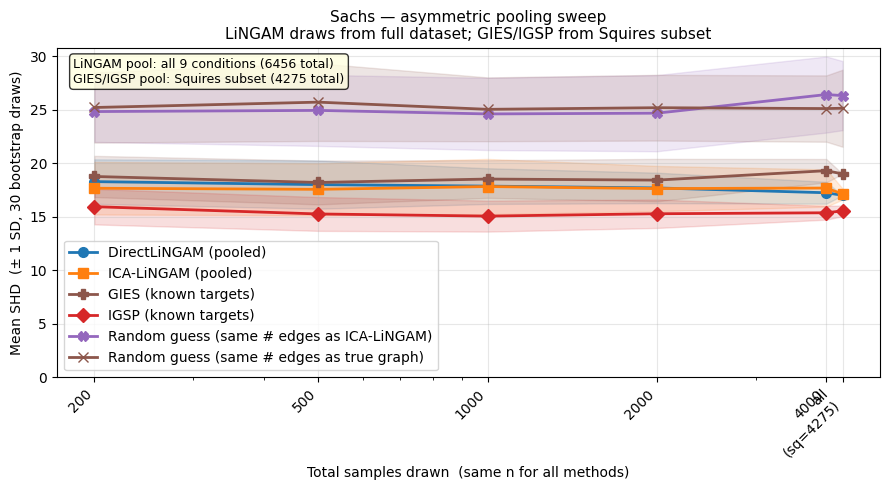

In [ ]:
N_SQUIRES = len(sq_data)   # 4275
N_FULL    = len(X_full)    # 6456

x2_numeric  = [s if s != 'all' else N_SQUIRES for s in TOTAL_SIZES]
x2_ticklabs = [str(s) if s != 'all' else f'all\n(sq={N_SQUIRES})' for s in TOTAL_SIZES]

fig, ax = plt.subplots(figsize=(9, 5))

for m in METHODS2:
    means = np.array([np.nanmean(boot2[m][s]) for s in TOTAL_SIZES])
    stds  = np.array([np.nanstd( boot2[m][s]) for s in TOTAL_SIZES])
    ax.plot(x2_numeric, means,
            color=SWEEP_COLORS[m], marker=SWEEP_MARKERS[m],
            lw=2, markersize=7, label=SWEEP_LABELS[m])
    print(m)
    if m != 'random_guess_groundtruth' and m!= 'random_guess_ica':  # skip error bars for random guess with true graph edge count (since it's not a real method)
        ax.fill_between(x2_numeric, means - stds, means + stds,
                    color=SWEEP_COLORS[m], alpha=0.15)

ax.text(0.02, 0.97,
        f'LiNGAM pool: all 9 conditions ({N_FULL} total)\n'
        f'GIES/IGSP pool: Squires subset ({N_SQUIRES} total)',
        transform=ax.transAxes, fontsize=9, va='top',
        bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.8))

ax.set_xscale('log')
ax.set_xticks(x2_numeric)
ax.set_xticklabels(x2_ticklabs, rotation=45, ha='right')
ax.set_xlabel('Total samples drawn  (same n for all methods)', fontsize=10)
ax.set_ylabel('Mean SHD  (± 1 SD, 30 bootstrap draws)', fontsize=10)
ax.set_title('Sachs — asymmetric pooling sweep\n'
             'LiNGAM draws from full dataset; GIES/IGSP from Squires subset', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('sachs_asymmetric_sweep.png', dpi=150, bbox_inches='tight')
plt.savefig('sachs_asymmetric_sweep.pdf', bbox_inches='tight')
plt.show()
